In [36]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout


In [21]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [22]:
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (50000, 32, 32, 3)
Testing data shape: (10000, 32, 32, 3)


In [23]:
print("Training minimum:", x_train.min())
print("Training maximum:", x_train.max())

print("Testing minimum:", x_test.min())
print("Testing maximum:", x_test.max())

Training minimum: 0
Training maximum: 255
Testing minimum: 0
Testing maximum: 255


In [24]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [25]:
print("Minimum:", x_test[0].min())
print("Maximum:", x_test[0].max())

Minimum: 0.050980393
Maximum: 1.0


In [26]:
# Class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]


In [27]:
# Step 4: Define the CNN model architecture

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [28]:
# Step 5: Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [29]:
# Display model architecture
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Step 6: Train the model

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.3050 - loss: 1.8787 - val_accuracy: 0.5147 - val_loss: 1.3658
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.4938 - loss: 1.4017 - val_accuracy: 0.5872 - val_loss: 1.1977
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.5516 - loss: 1.2673 - val_accuracy: 0.6201 - val_loss: 1.1081
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.5897 - loss: 1.1697 - val_accuracy: 0.6396 - val_loss: 1.0380
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.6170 - loss: 1.0945 - val_accuracy: 0.6416 - val_loss: 1.0138
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6288 - loss: 1.0558 - val_accuracy: 0.6540 - val_loss: 0.9783
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.6543 - loss: 0.9852 - val_accuracy: 0.6707 - val_loss: 0.9508
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6685 - loss: 0.9445 - 

In [31]:
# Step 7: Estimate model performance

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7008 - loss: 0.8773
Test Loss: 0.8842556476593018
Test Accuracy: 69.73000168800354 %


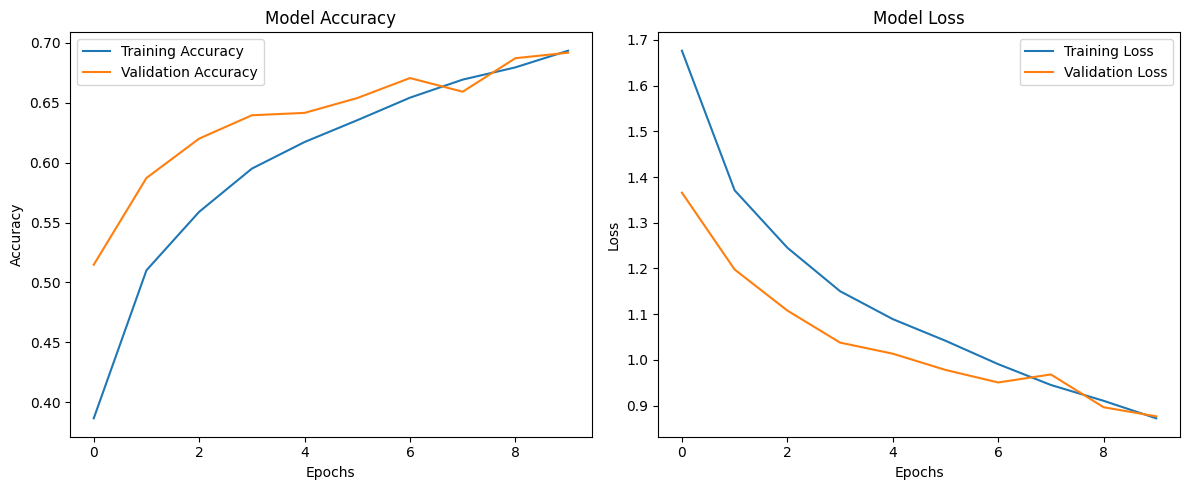

In [32]:
# Step 8: Plot training and validation accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


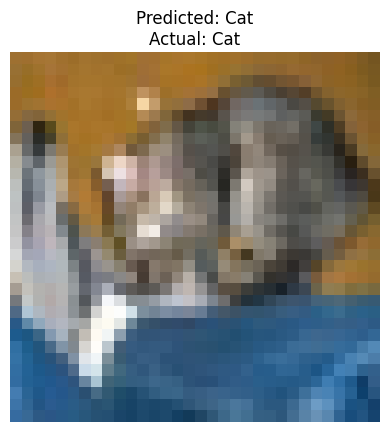

In [33]:
# Step 9: Predict one test image

predictions = model.predict(x_test[:1])

predicted_class = np.argmax(predictions[0])
actual_class = int(y_test[0][0])

plt.imshow(x_test[0])
plt.title(
    "Predicted: " + class_names[predicted_class] +
    "\nActual: " + class_names[actual_class]
)
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


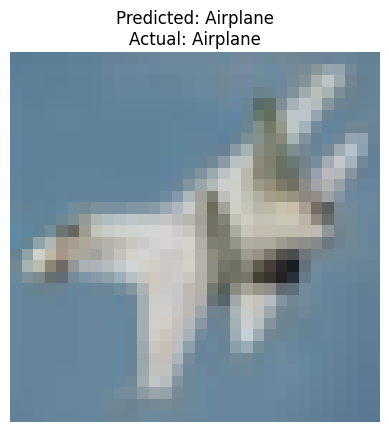

In [34]:
# Step 9: Predict another test image

image_index = 10

predictions = model.predict(x_test[image_index:image_index+1])

predicted_class = np.argmax(predictions[0])
actual_class = int(y_test[image_index][0])

plt.imshow(x_test[image_index])
plt.title(
    "Predicted: " + class_names[predicted_class] +
    "\nActual: " + class_names[actual_class]
)
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


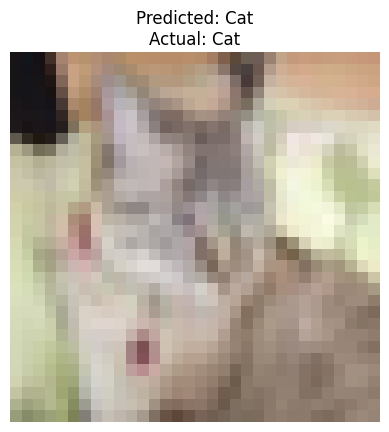

In [48]:
# Predict one test image

index =8 # Change this index to select another image

predictions = model.predict(x_test[index:index+1])

predicted_class = np.argmax(predictions[0])
actual_class = int(y_test[index][0])

plt.imshow(x_test[index])

plt.title(
    "Predicted: " + class_names[predicted_class] +
    "\nActual: " + class_names[actual_class]
)

plt.axis('off')
plt.show()
